In [1]:
import multiprocessing
import threading
import time

In [4]:


# Two 3x3 matrices
A = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
]

B = [
    [9, 8, 7],
    [6, 5, 4],
    [3, 2, 1]
]

N = 3


# ---------------- SEQUENTIAL ----------------

def sequential():
    C = [[0] * N for _ in range(N)]

    for i in range(N):
        for j in range(N):
            C[i][j] = A[i][j] + B[i][j]

    return C


start = time.perf_counter()
C1 = sequential()
seq_time = time.perf_counter() - start


# ---------------- POOL ----------------

def add_row(data):
    row1, row2 = data
    return [x + y for x, y in zip(row1, row2)]


start = time.perf_counter()

with multiprocessing.Pool(3) as pool:
    C2 = pool.map(add_row, zip(A, B))

pool_time = time.perf_counter() - start


# ---------------- PROCESS ----------------


def add_process(row, queue):

    result = []

    for j in range(N):
        result.append(A[row][j] + B[row][j])

    queue.put((row, result))


if __name__ == "__main__":

    C3 = [[0] * N for _ in range(N)]

    queue = multiprocessing.Queue()
    processes = []

    start = time.perf_counter()

    for i in range(N):

        p = multiprocessing.Process(
            target=add_process,
            args=(i, queue)
        )

        processes.append(p)
        p.start()

    # Get results from processes
    for i in range(N):

        row, result = queue.get()

        C3[row] = result

    # Wait for processes
    for p in processes:
        p.join()

    process_time = time.perf_counter() - start

    # ---------------- MULTITHREADING ----------------

    C4 = [[0] * N for _ in range(N)]

    def add_thread(row):
        for j in range(N):
            C4[row][j] = A[row][j] + B[row][j]


    threads = []

    start = time.perf_counter()

    for i in range(N):
        t = threading.Thread(
            target=add_thread,
            args=(i,)
        )

        threads.append(t)
        t.start()

    for t in threads:
        t.join()

    thread_time = time.perf_counter() - start


    # ---------------- RESULTS ----------------

    print("Matrix A:")
    for row in A:
        print(row)

    print("\nMatrix B:")
    for row in B:
        print(row)

    print("\nResult using Sequential:")
    for row in C1:
        print(row)

    print("\nResult using Pool:")
    for row in C2:
        print(row)

    print("\nResult using Process:")
    for row in C3:
        print(row)

    print("\nResult using Threading:")
    for row in C4:
        print(row)


    # Execution Time

    print("\nExecution Time:")
    print("Sequential :", seq_time)
    print("Pool       :", pool_time)
    print("Process    :", process_time)
    print("Threading  :", thread_time)


    # Speedup

    print("\nSpeedup:")
    print("Sequential :", 1)
    print("Pool       :", seq_time / pool_time)
    print("Process    :", seq_time / process_time)
    print("Threading  :", seq_time / thread_time)

Matrix A:
[1, 2, 3]
[4, 5, 6]
[7, 8, 9]

Matrix B:
[9, 8, 7]
[6, 5, 4]
[3, 2, 1]

Result using Sequential:
[10, 10, 10]
[10, 10, 10]
[10, 10, 10]

Result using Pool:
[10, 10, 10]
[10, 10, 10]
[10, 10, 10]

Result using Process:
[10, 10, 10]
[10, 10, 10]
[10, 10, 10]

Result using Threading:
[10, 10, 10]
[10, 10, 10]
[10, 10, 10]

Execution Time:
Sequential : 0.00012420900020515546
Pool       : 0.043392215000494616
Process    : 0.04106929600038711
Threading  : 0.0008077820002654335

Speedup:
Sequential : 1
Pool       : 0.00286247199419849
Process    : 0.0030243761715317615
Threading  : 0.15376549633978098


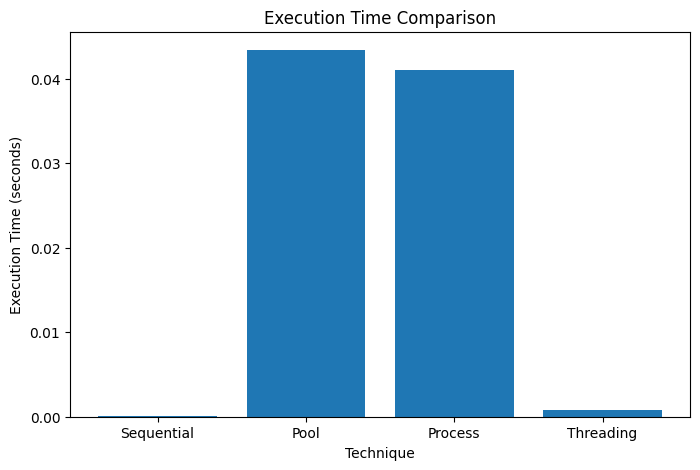

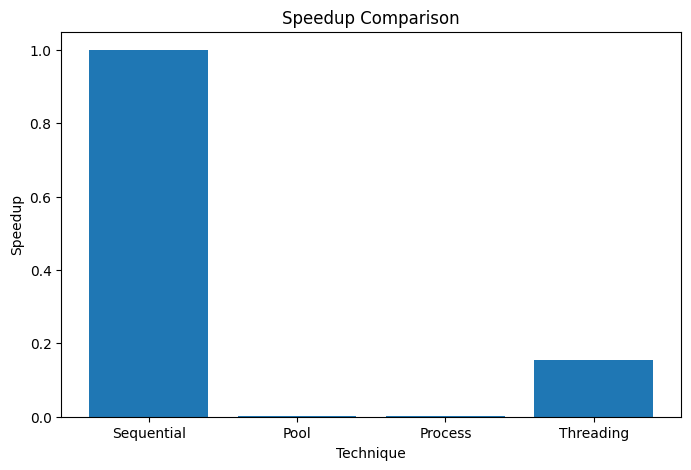

In [5]:
import matplotlib.pyplot as plt

# Values for graph
methods = ["Sequential", "Pool", "Process", "Threading"]

execution_times = [
    seq_time,
    pool_time,
    process_time,
    thread_time
]

speedups = [
    1,
    seq_time / pool_time,
    seq_time / process_time,
    seq_time / thread_time
]


# -------- EXECUTION TIME GRAPH --------

plt.figure(figsize=(8, 5))

plt.bar(methods, execution_times)

plt.xlabel("Technique")
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time Comparison")

plt.show()


# -------- SPEEDUP GRAPH --------

plt.figure(figsize=(8, 5))

plt.bar(methods, speedups)

plt.xlabel("Technique")
plt.ylabel("Speedup")
plt.title("Speedup Comparison")

plt.show()